### calculate theoretical KMD

In [ ]:
import numpy as np

# linterature masses
mass_C12 = 12.000000
mass_C13 = 13.00335483507
mass_H   = 1.007825
mass_O   = 15.994915
mass_N   = 14.003074
mass_e   = 0.000548579909065  # mass of an electron

# CH2-basis for Kendrick analyis
exact_CH2 = mass_C12 + 2*mass_H
nominal_CH2 = 14.00000
kendrick_factor = nominal_CH2 / exact_CH2

def kendrick_values(formula, positive_mode=True, C13_count=0):
    """
    calculates Exact Mass, Kendrick Mass, Kendrick Nominal Mass and KMD
    
    formula: dict with number of carbon atoms (total carbon number in 'C')
    positive_mode: True for positive mode with substraction of electron mass
    C13_count: number of 13C atoms in molecule
    """
    C12_count = formula.get('C', 0) - C13_count
    
    # 1: exact mass
    exact_mass = (
        C12_count * mass_C12 +
        C13_count * mass_C13 +
        formula.get('H', 0) * mass_H +
        formula.get('O', 0) * mass_O +
        formula.get('N', 0) * mass_N
    )
    
    # 2: correct for electrons
    if positive_mode:
        exact_mass -= mass_e
    
    # 3: calculate kendrick mass
    km = exact_mass * kendrick_factor
    
    # 4: calculate kendrick nominal mass
    knm = np.floor(km + 0.5)
    
    # 5: calculate kendrick mass defect
    kmd = knm - km
    
    return exact_mass, km, knm, kmd

# Basis: C17H34 DBE=1
base = {'C': 17, 'H': 34}

# Adducts differing to base
adducts = {
    "[M]+": {},
    "[M+O-3H]+": {'O': 1, 'H': -3},
    "[M+2O-3H]+": {'O': 2, 'H': -3},
    "[M+NO]+": {'N': 1, 'O': 1}
}

for name, add in adducts.items():
    # modify base formula for adduct
    formula = base.copy()
    for atom, cnt in add.items():
        formula[atom] = formula.get(atom, 0) + cnt
    
    # monoisotopic KMD
    exact_mass, km, knm, kmd = kendrick_values(formula, positive_mode=True, C13_count=0)
    # 13C1-Isotop
    exact_mass_iso, km_iso, knm_iso, kmd_iso = kendrick_values(formula, positive_mode=True, C13_count=1)
    
    print(f"{name} MONO: Exact={exact_mass:.6f} u, KM={km:.6f}, KMD={kmd*1000:.3f} ")
    print(f"{name} ^13C1: Exact={exact_mass_iso:.6f} u, KM={km_iso:.6f}, KMD={kmd_iso*1000:.3f} ")
    print(f"ΔKMD durch 1x13C: {(kmd_iso - kmd)*1000:.3f} \n")

[M]+ MONO: Exact=238.265501 u, KM=237.999452, KMD=0.548 
[M]+ ^13C1: Exact=239.268856 u, KM=239.001687, KMD=-1.687 
ΔKMD durch 1x13C: -2.234 

[M+O-3H]+ MONO: Exact=251.236941 u, KM=250.956408, KMD=43.592 
[M+O-3H]+ ^13C1: Exact=252.240296 u, KM=251.958642, KMD=41.358 
ΔKMD durch 1x13C: -2.234 

[M+2O-3H]+ MONO: Exact=267.231856 u, KM=266.933463, KMD=66.537 
[M+2O-3H]+ ^13C1: Exact=268.235211 u, KM=267.935697, KMD=64.303 
ΔKMD durch 1x13C: -2.234 

[M+NO]+ MONO: Exact=268.263490 u, KM=267.963945, KMD=36.055 
[M+NO]+ ^13C1: Exact=269.266845 u, KM=268.966179, KMD=33.821 
ΔKMD durch 1x13C: -2.234 



### KMD analysis

### import csv files '_kendrick.csv'

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import time
import os
from matplotlib.colors import LinearSegmentedColormap

def load_kendrick_csv(filename, sep=","):
    """load csv file and return as dataframe"""
    df = pd.read_csv(filename, sep=sep)
    return df

# === example for multiple samples ===
csv_files = [
    #("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-01_kendrick.csv", "Input/iLTP_ORBI_0-01"),
    ("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-001_kendrick.csv", "Input/iLTP_ORBI_0-001"),
    #("Input/250828_Ar_pos_P_MS1_pos_ORBI_01_scan_34tol0-0001_kendrick.csv", "Input/iLTP_ORBI_0-0001"),
    ("Input/250828_Ar_pos_P_MS1_pos_OSAF_03_cluster_scan_33tol0-001_kendrick.csv", "Input/iLTP_OSAF_0-001")
]

if __name__ == "__main__":
    for file_path, output_name in csv_files:
        df = load_kendrick_csv(file_path)
        out_filename = f"{output_name}.pkl"
        df.to_pickle(out_filename)
        print(f"[INFO] saved: {out_filename} ({len(df)} Zeilen)")

[INFO] saved: Input/iLTP_ORBI_0-001.pkl (2514 Zeilen)
[INFO] saved: Input/iLTP_OSAF_0-001.pkl (2261 Zeilen)


### KMD Analyse - gibt Excel-Arbeitsmappe als Output

In [3]:
import pandas as pd
import numpy as np
import time

def analyze_kendrick_df(df,
                        ion_source="", 
                        sample="",
                        intensity_min=8e+6,
                        tol=0.001,             # KMD tolerance in u (~m/z tolerance)
                        max_dbe_steps=20,              # ± number of half DBE steps
                        max_iso=1,             # number of maximum 13C isotopes
                        realistic_dbe_min=-2,
                        realistic_dbe_max=10,
                        DBE_step_size=0.0134,             # u for each full DBE step
                        mass_error_tolerance_ppm=10.0,
                        output_prefix="analysis", 
                        save_excel=True):
    """analyses Kednrick files, returns extended dataframe"""
    
    # === constant values ===
    mass_C12 = 12.000000
    mass_C13 = 13.003355
    mass_H   = 1.007825
    mass_O   = 15.994915
    mass_N   = 14.003074
    mass_e   = 0.000549
    exact_CH2 = mass_C12 + 2 * mass_H
    kendrick_factor = 14.00000 / exact_CH2
    
    def kendrick_values(formula, positive_mode=True, C13_count=0):
        C12_count = formula.get('C', 0) - C13_count
        exact_mass = (
            C12_count * mass_C12 +
            C13_count * mass_C13 +
            formula.get('H', 0) * mass_H +
            formula.get('O', 0) * mass_O +
            formula.get('N', 0) * mass_N
        )
        if positive_mode:
            exact_mass -= mass_e
        km = exact_mass * kendrick_factor
        knm = np.floor(km + 0.5)
        kmd = knm - km
        return exact_mass, km, knm, kmd
    
    # === adduct definition ===
    base = {'C': 17, 'H': 34}
    adducts = {
        "[M]$^+$": {},
        "[M+O-3H]$^+$": {'O': 1, 'H': -3},
        "[M+2O-3H]$^+$": {'O': 2, 'H': -3},
        "[M+3O-3H]$^+$": {'O': 3, 'H': -3},
        "[M+4O-3H]$^+$": {'O': 4, 'H': -3},
    }
    
#[M+4O-3H]⁺

    # === helper functions DBE / C / H / Mass Error ===
    def round_to_half(val):
        return round(val * 2) / 2.0
    
    def calc_c_number(knm_measured, adduct, dbe_value):  # calculates even numbered carbon number from KNM and adduct correction
        if adduct not in knm_adduct_offsets or dbe_value is None:
            return None
        knm_adduct = knm_adduct_offsets[adduct]
        return int(round((knm_measured - knm_adduct - (2 - 2 * dbe_value)) / 14))
    
    def calc_h_number(c_value, dbe_value):
        if c_value is None or dbe_value is None:
            return None
        return int(round(-2 * dbe_value + 2 * c_value + 2))
    
    def calc_mass_error_ppm(mass_measured, c_value, h_value, adduct, iso_count=0, charge=1): # if necessary modify charge state
        if None in (mass_measured, c_value, h_value):
            return None
        c12_count = c_value - iso_count
        c13_count = iso_count
        mass_theor = (c12_count * mass_C12) + (c13_count * mass_C13) + (h_value * mass_H)
        # adduct correction
        for atom, cnt in adducts.get(adduct, {}).items():
            if atom == 'C': mass_theor += cnt * mass_C12
            elif atom == 'H': mass_theor += cnt * mass_H
            elif atom == 'O': mass_theor += cnt * mass_O
            elif atom == 'N': mass_theor += cnt * mass_N
        # electron correction
        if charge > 0:
            mass_theor -= mass_e * charge
        return ((mass_measured - mass_theor) / mass_theor) * 1e6
    
    # === reference KMD table ===
    # === 1: calculate theoretical values & KMD adduct offset ===
    reference_kmds = {}
    knm_adduct_offsets = {}
    theoretical_kmds = []
    
    for adduct, add_comp in adducts.items():
        _, km_base, _, _ = kendrick_values(base, True, C13_count=0)
        formula_plus = base.copy()
        for atom, cnt in add_comp.items():
            formula_plus[atom] = formula_plus.get(atom, 0) + cnt
        _, km_plus, knm_plus, kmd_plus = kendrick_values(formula_plus, True, C13_count=0)
        reference_kmds[adduct] = kmd_plus
        knm_adduct_offsets[adduct] = round(km_plus - km_base, 6)
        # for all DBE and isotopes
        for step in range(-max_dbe_steps, max_dbe_steps + 1):
            for iso in range(0, max_iso + 1):
                _, _, _, kmd_iso = kendrick_values(formula_plus, True, C13_count=iso)
                kmd_theor = kmd_iso + step * (DBE_step_size / 2)
                theoretical_kmds.append({
                    "adduct": adduct, "iso": iso, "dbe": step, "kmd_theor": kmd_theor
                })
    kmd_ref_df = pd.DataFrame(theoretical_kmds)
    
    def calc_dbe_and_diff(kmd_measured, adduct):
        if adduct not in reference_kmds: return None, None
        kmd_ref = reference_kmds[adduct]
        dbe_raw = (kmd_measured - kmd_ref + DBE_step_size) / DBE_step_size
        return dbe_raw, abs(dbe_raw - round_to_half(dbe_raw))
    
    # === 2: Matching with KMD table ===
    def assign_best_match(kmd_obs):
        matches = []
        for _, ref in kmd_ref_df.iterrows():
            diff_kmd = abs(kmd_obs - ref['kmd_theor'])
            if diff_kmd <= tol:              
                dbe_raw, dbe_diff = calc_dbe_and_diff(kmd_obs, ref['adduct'])
                matches.append({
                    "adduct": ref['adduct'],
                    "iso": ref['iso'],
                    "dbe_match": ref['dbe'],
                    "diff_kmd": diff_kmd,
                    "dbe_raw": dbe_raw,
                    "dbe_round": round_to_half(dbe_raw),
                    "dbe_diff": dbe_diff
                })
        realistic = [m for m in matches if m["dbe_raw"] is not None and realistic_dbe_min <= m["dbe_raw"] <= realistic_dbe_max]
        if not realistic: return "Unknown", None, None, None, None, None
        # priority: 1. diff_kmd, 2. dbe_diff
        best = sorted(realistic, key=lambda x: (x["diff_kmd"], x["dbe_diff"]))[0]
        return best["adduct"], best["iso"], best["dbe_match"], best["dbe_raw"], best["dbe_round"], best["dbe_diff"]
    
    # === 3: cutoff ===
    df = df[df['intensity'] >= intensity_min].copy()

    # === 4: calculations ===
    adduct_list, iso_list, dbe_step_list, dbe_raw_list, dbe_round_list, dbe_diff_list, c_number_list, h_number_list, mass_error_list = [], [], [], [], [], [], [], [], []
    
    for _, row in df.iterrows():
        a, i, dbe_match, dbe_raw, dbe_round, dbe_diff = assign_best_match(row['KMD'])
        c_val = calc_c_number(row['KNM'], a, dbe_round)
        h_val = calc_h_number(c_val, dbe_round)
        mass_err_ppm = calc_mass_error_ppm(row['mz'], c_val, h_val, a, iso_count=i if i is not None else 0)
        if mass_err_ppm is None or abs(mass_err_ppm) > mass_error_tolerance_ppm:
            a, i, dbe_match, dbe_raw, dbe_round, dbe_diff, c_val, h_val, mass_err_ppm = "Unknown", None, None, None, None, None, None, None, None
        adduct_list.append(a); iso_list.append(i)
        dbe_step_list.append(dbe_match); dbe_raw_list.append(dbe_raw)
        dbe_round_list.append(dbe_round); dbe_diff_list.append(dbe_diff)
        c_number_list.append(c_val); h_number_list.append(h_val); mass_error_list.append(mass_err_ppm)
    
    # === prepare results dataframe ===
    df['Adduct'] = adduct_list
    df['13C_count'] = iso_list
    df['DBE_step_match'] = dbe_step_list
    df['DBE_calc_raw'] = dbe_raw_list
    df['DBE_calc_rounded'] = dbe_round_list
    df['DBE_round_diff'] = dbe_diff_list
    df['C_number'] = c_number_list
    df['H_number'] = h_number_list
    df['Formula'] = [f"C{c}H{h}" if c is not None and h is not None else None for c, h in zip(c_number_list, h_number_list)]
    df['Mass_error_ppm'] = mass_error_list

    # === 5: export to xlsx ===
    if save_excel:
        safe_ion = ion_source.replace(" ", "_")
        safe_sample = sample.replace(" ", "_")
        filename = f"Output/{safe_ion}_{safe_sample}_{output_prefix}_results_KMD.xlsx"
        df.to_excel(filename, index=False)
        print(f"[INFO] Excel saved: {filename}")

    total_peaks = len(df)
    matched_peaks = (df['Adduct'] != "Unknown").sum()
    unknown_peaks = (df['Adduct'] == "Unknown").sum()

    print("\n=== Matching Summary ===")
    print(f"Total peaks processed: {total_peaks}")
    print(f"Matched peaks: {matched_peaks}")
    print(f"Unknown peaks: {unknown_peaks}")
    print("========================\n")

    return df

### KMD vs KNM plots

In [5]:
plt.rcParams.update({
    "font.size": 8, #10 for report, 8 for publication
    "axes.labelsize": 8, #10 for report, 8 for publication
    "axes.titlesize": 8, #10 for report, 8 for publication
    "xtick.labelsize": 6, #10 for report, 6 for publication
    "ytick.labelsize": 6, #10 for report, 6 for publication
    "legend.fontsize": 8, #10 for report, 8 for publication
    "figure.titlesize": 8, #10 for report, 8 for publication
    "font.family": "Arial"
})

In [ ]:
def plot_kmd_vs_knm_publication(df, ion_source, sample, output_prefix):
    """KMD plot from results dataframe."""
    cm_to_inch = 0.393701
    fig_width = 10.99 * cm_to_inch
    fig_height = 4 * cm_to_inch
    label_fontsize = 8
    tick_fontsize = 6
    title_fontsize = 8
    palette = ["#000000","#004c93ff",  "#ec7106ff", "#61a27cff", "#b8103aff", "#fecb00ff"]
    color_map = {a: mcolors.to_rgb(palette[i % len(palette)]) for i, a in enumerate(df['Adduct'].unique())}
    markers = {0: 'o', 1: '^'}
    marker_unknown = 'x'
    unknown_subset = df[df['Adduct'] == "Unknown"]
    intensity_min = 0 #muss evtl. angepasst werden, wenn cutoff angewendet wird

    
    # Plot: Punktgröße = Intensität (120 - 0.5)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=1200)

    fig.subplots_adjust(
        left=0.12,
        right=0.6,
        top=0.95,
        bottom=0.25
    )
    legend_entries_size = {}
    int_max = df['intensity'].max()
    size_from_intensity = lambda val: 0.5 + (80 - 0.5) * max(0, (val - intensity_min) / (int_max - intensity_min))
    for adduct in [a for a in df['Adduct'].unique() if a != "Unknown"]:
        for iso in sorted(df['13C_count'].dropna().unique()):
            subset = df[(df['Adduct'] == adduct) & (df['13C_count'] == iso)]
            if subset.empty: continue
            rgb_color = color_map.get(adduct, (0,0,0))
            sizes = [size_from_intensity(val) for val in subset['intensity']]
            plt.scatter(subset['KNM'], subset['KMD'], marker=markers.get(iso, 'o'), s=sizes,
                        facecolors=(rgb_color[0], rgb_color[1], rgb_color[2], 0.4),
                        edgecolors=(rgb_color[0], rgb_color[1], rgb_color[2], 1.0), linewidths=0.5)
            legend_label = f"{adduct} only ¹²C" if iso==0 else f"{adduct} 1×¹³C" if iso==1 else f"{adduct} {iso}×¹³C"
            legend_entries_size[legend_label] = {"color": (rgb_color[0], rgb_color[1], rgb_color[2], 1.0),
                                                 "marker": markers.get(iso, 'o')}
    if not unknown_subset.empty:
        sizes_u = [size_from_intensity(val) for val in unknown_subset['intensity']]
        plt.scatter(unknown_subset['KNM'], unknown_subset['KMD'], marker='x', s=sizes_u,
                    facecolors=(0,0,0,0.4), edgecolors=(0,0,0,1.0), linewidths=0.5)
        legend_entries_size["Unknown"] = {"color": (0,0,0,1.0), "marker": 'x'}

    handles = [plt.Line2D([], [], color=info["color"],
                           marker=info["marker"], linestyle='',
                           markerfacecolor=(info["color"][0], info["color"][1], info["color"][2], 0.4),
                           markeredgecolor=info["color"], markersize=2) for label, info in legend_entries_size.items()]
    labels = list(legend_entries_size.keys())

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.xlabel("KNM", fontsize=label_fontsize)
    plt.ylabel("KMD", fontsize=label_fontsize)
    plt.ylim(-0.025, 0.2)
    plt.xlim(50, 650)
    plt.tick_params(axis='both', labelsize=tick_fontsize)
    #plt.title(f"KMD vs KNM \n {ion_source}, {sample}", fontsize=title_fontsize, fontweight="bold")
    plt.legend(handles, labels, markerscale=2, bbox_to_anchor=(1.1, 1.05), loc='upper left', fontsize=6, frameon=False)
    #plt.tight_layout()
    plt.savefig(f"Output/Ver2_{ion_source}_{sample}_{output_prefix}_KMDvKNM.png", dpi=1200)
    plt.show()

In [8]:
from matplotlib.ticker import MultipleLocator
def plot_dbe_vs_c_publication(df, ion_source, sample, adduct_to_plot, output_prefix, point_size=10):
    """Plot DBE vs Carbon Number for specified adduct"""
    cmap = LinearSegmentedColormap.from_list('my cmap',
        ['#ffffff','#457B9D','#355E80','#2E5375','#32664D','#39AE29','#40FF00','#ffff00','#ffc000','#ff0000','#C00000'])
    cm_to_inch = 0.393701
    fig_width = 5.496 * cm_to_inch
    fig_height = 4 * cm_to_inch
    label_fontsize = 8
    title_fontsize = 6

    df_adduct = df[df['Adduct'] == adduct_to_plot].copy()
    if df_adduct.empty:
        raise ValueError(f"Adduct '{adduct_to_plot}' not found. Availabe adducts: {df['Adduct'].unique()}")
    df_adduct = df_adduct.sort_values(by='intensity', ascending=True)

    # Plot 3
    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=1200)
    sc = plt.scatter(df_adduct['C_number'], df_adduct['DBE_calc_rounded'],
                     c=df_adduct['intensity'], cmap=cmap, s=point_size,
                     edgecolors='black', lw=0.5)
    fig.subplots_adjust(
        left=0.2,
        right=0.9,
        top=0.86,
        bottom=0.24
    )
    plt.xlabel("carbon number", fontsize=label_fontsize)
    plt.ylabel("DBE", fontsize=label_fontsize)
    ax.set_title(f"Adduct: {adduct_to_plot}")
    plt.colorbar(sc, label="intensity")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"Output/Ver2_{ion_source}_{sample}_{output_prefix}_plot3_DBE_{adduct_to_plot}.png", dpi=1200)
    plt.show()

    # Plot 4
    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=1200)
    sc = plt.scatter(df_adduct['C_number'], df_adduct['DBE_calc_rounded'],
                     c=df_adduct['intensity'], cmap=cmap, s=point_size,
                     edgecolors='black', lw=0.5)
    fig.subplots_adjust(
        left=0.2,
        right=0.9,
        top=0.86,
        bottom=0.24
    )
    plt.xlabel("carbon number", fontsize=label_fontsize)
    plt.ylabel("DBE", fontsize=label_fontsize)
    ax.set_title(f"Adduct: {adduct_to_plot}")
    plt.ylim(-1, 6)
    plt.xlim(0, 38)
    plt.tick_params(axis='both', labelsize=6)
    for y in range(-1, 8):
        plt.axhline(y, color='grey', ls='dotted', lw=1)
    plt.colorbar(sc, label="intensity")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.xaxis.set_major_locator(MultipleLocator(5))
    ax.yaxis.set_major_locator(MultipleLocator(1))
    plt.tight_layout()
    plt.savefig(f"Output/Ver2_{ion_source}_{sample}_{output_prefix}_plot4_DBE_{adduct_to_plot}.png", dpi=1200)
    plt.show()

In [9]:
df_results = analyze_kendrick_df(
    pd.read_pickle("Input/iLTP_ORBI_0-001.pkl"),
    ion_source="iLTP Ar(+) MS(+)",
    sample="C2C-007",
    output_prefix="no_cutoff_0-001",
    intensity_min=0 # intensity cutoff einstellen
)

[INFO] Excel saved: Output/iLTP_Ar(+)_MS(+)_C2C-007_no_cutoff_0-001_results_KMD.xlsx

=== Matching Summary ===
Total peaks processed: 2514
Matched peaks: 1068
Unknown peaks: 1446



C:\Users\Sebastian\AppData\Local\Temp\ipykernel_14848\290915873.py:43: UserWarning: You passed a edgecolor/edgecolors ((0, 0, 0, 1.0)) for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(unknown_subset['KNM'], unknown_subset['KMD'], marker='x', s=sizes_u,


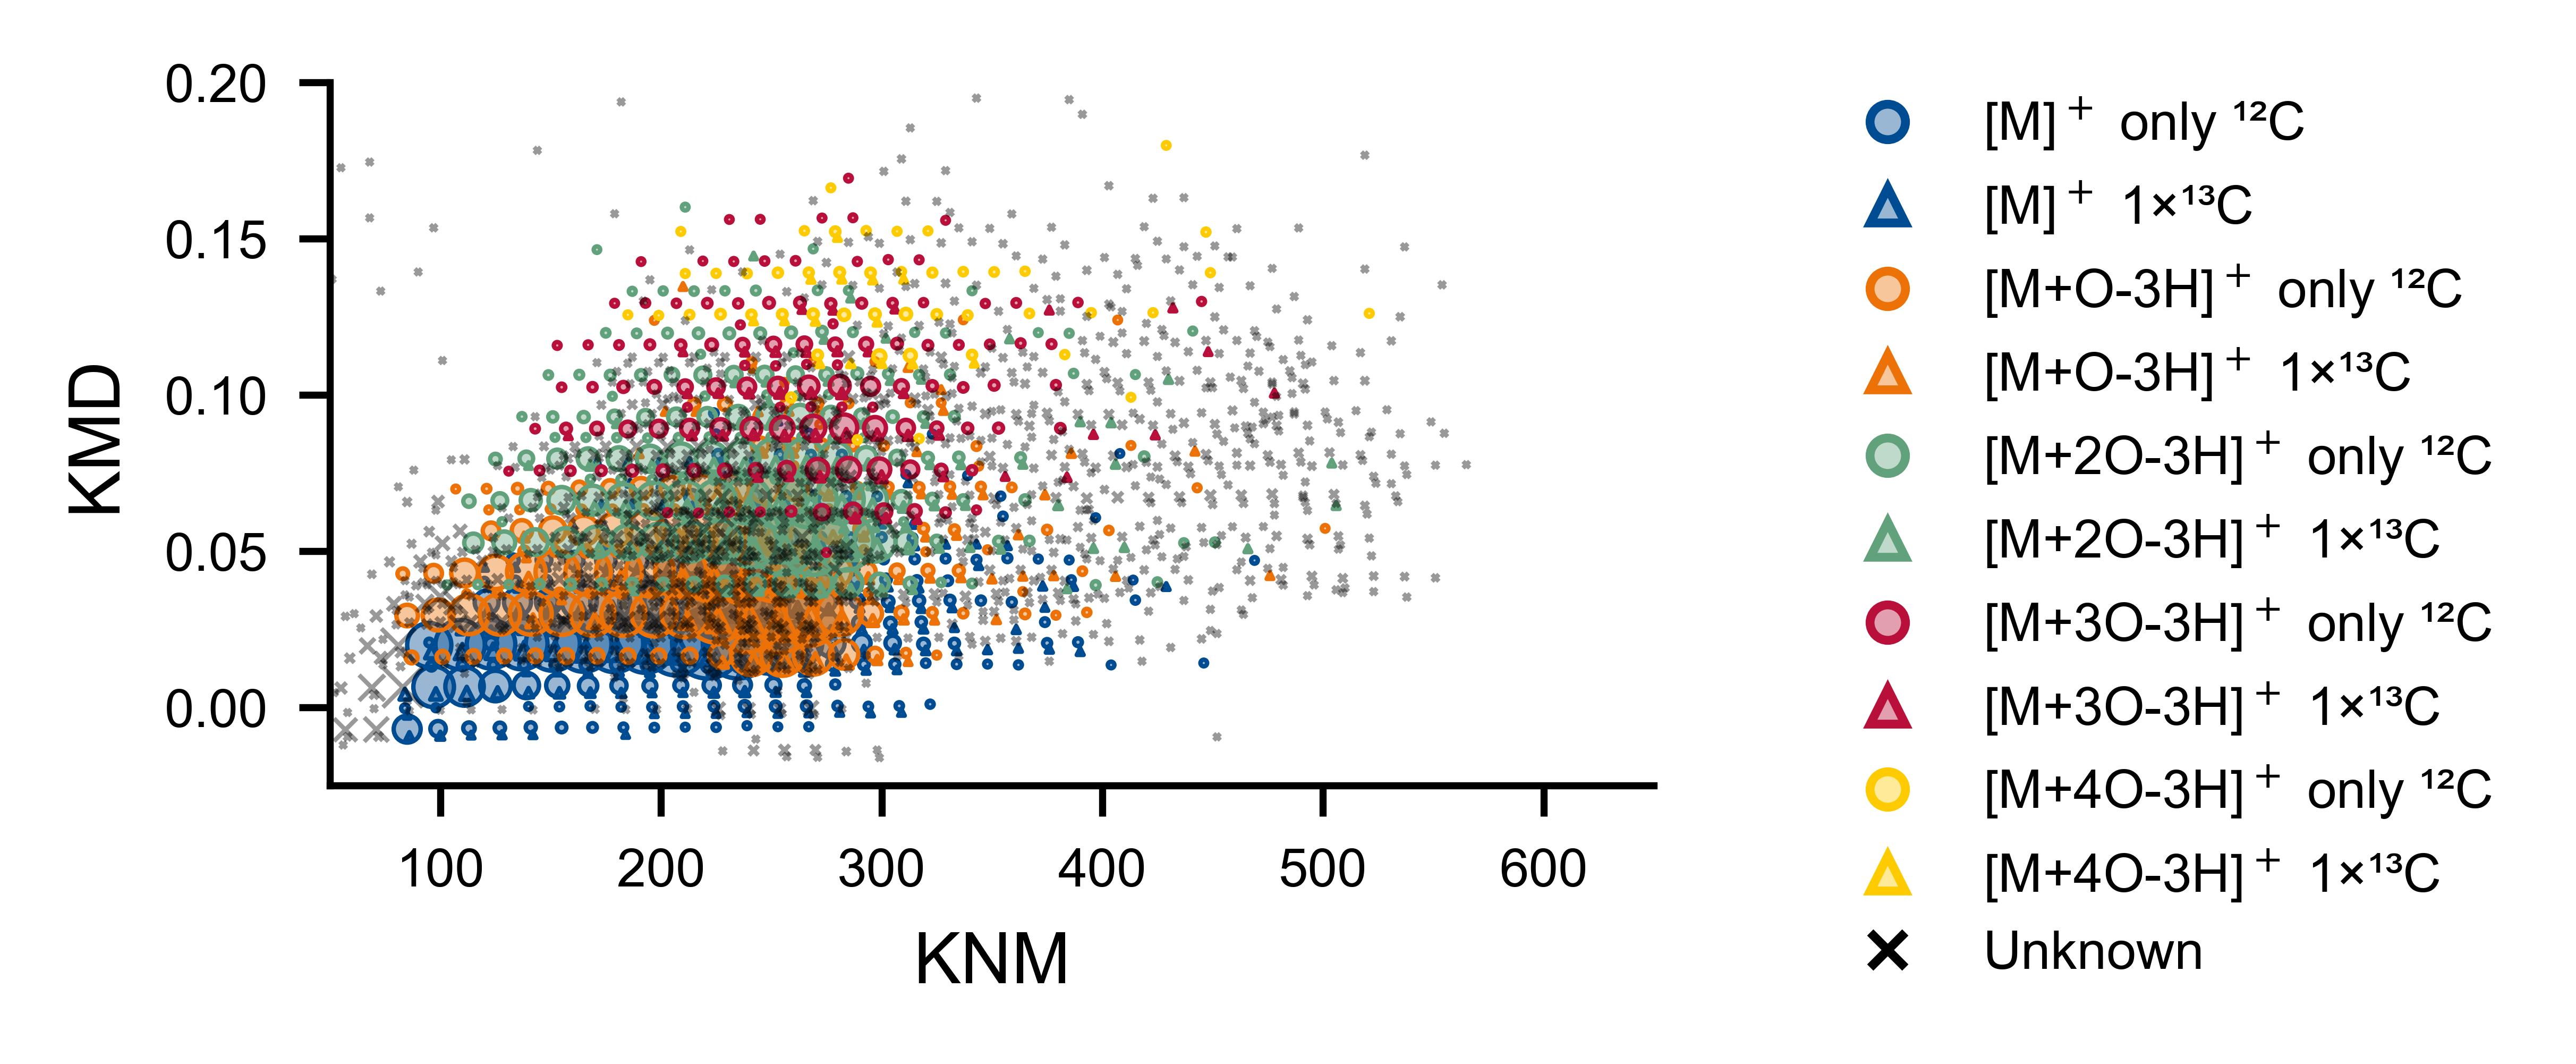

In [10]:
# 2) KMD-Plots für gesamte Probe
plot_kmd_vs_knm_publication(df_results, 
                ion_source="iLTP Ar(+) MS(+)", 
                sample="C2C-007", 
                output_prefix="no_cutoff_0-001_new"
                )


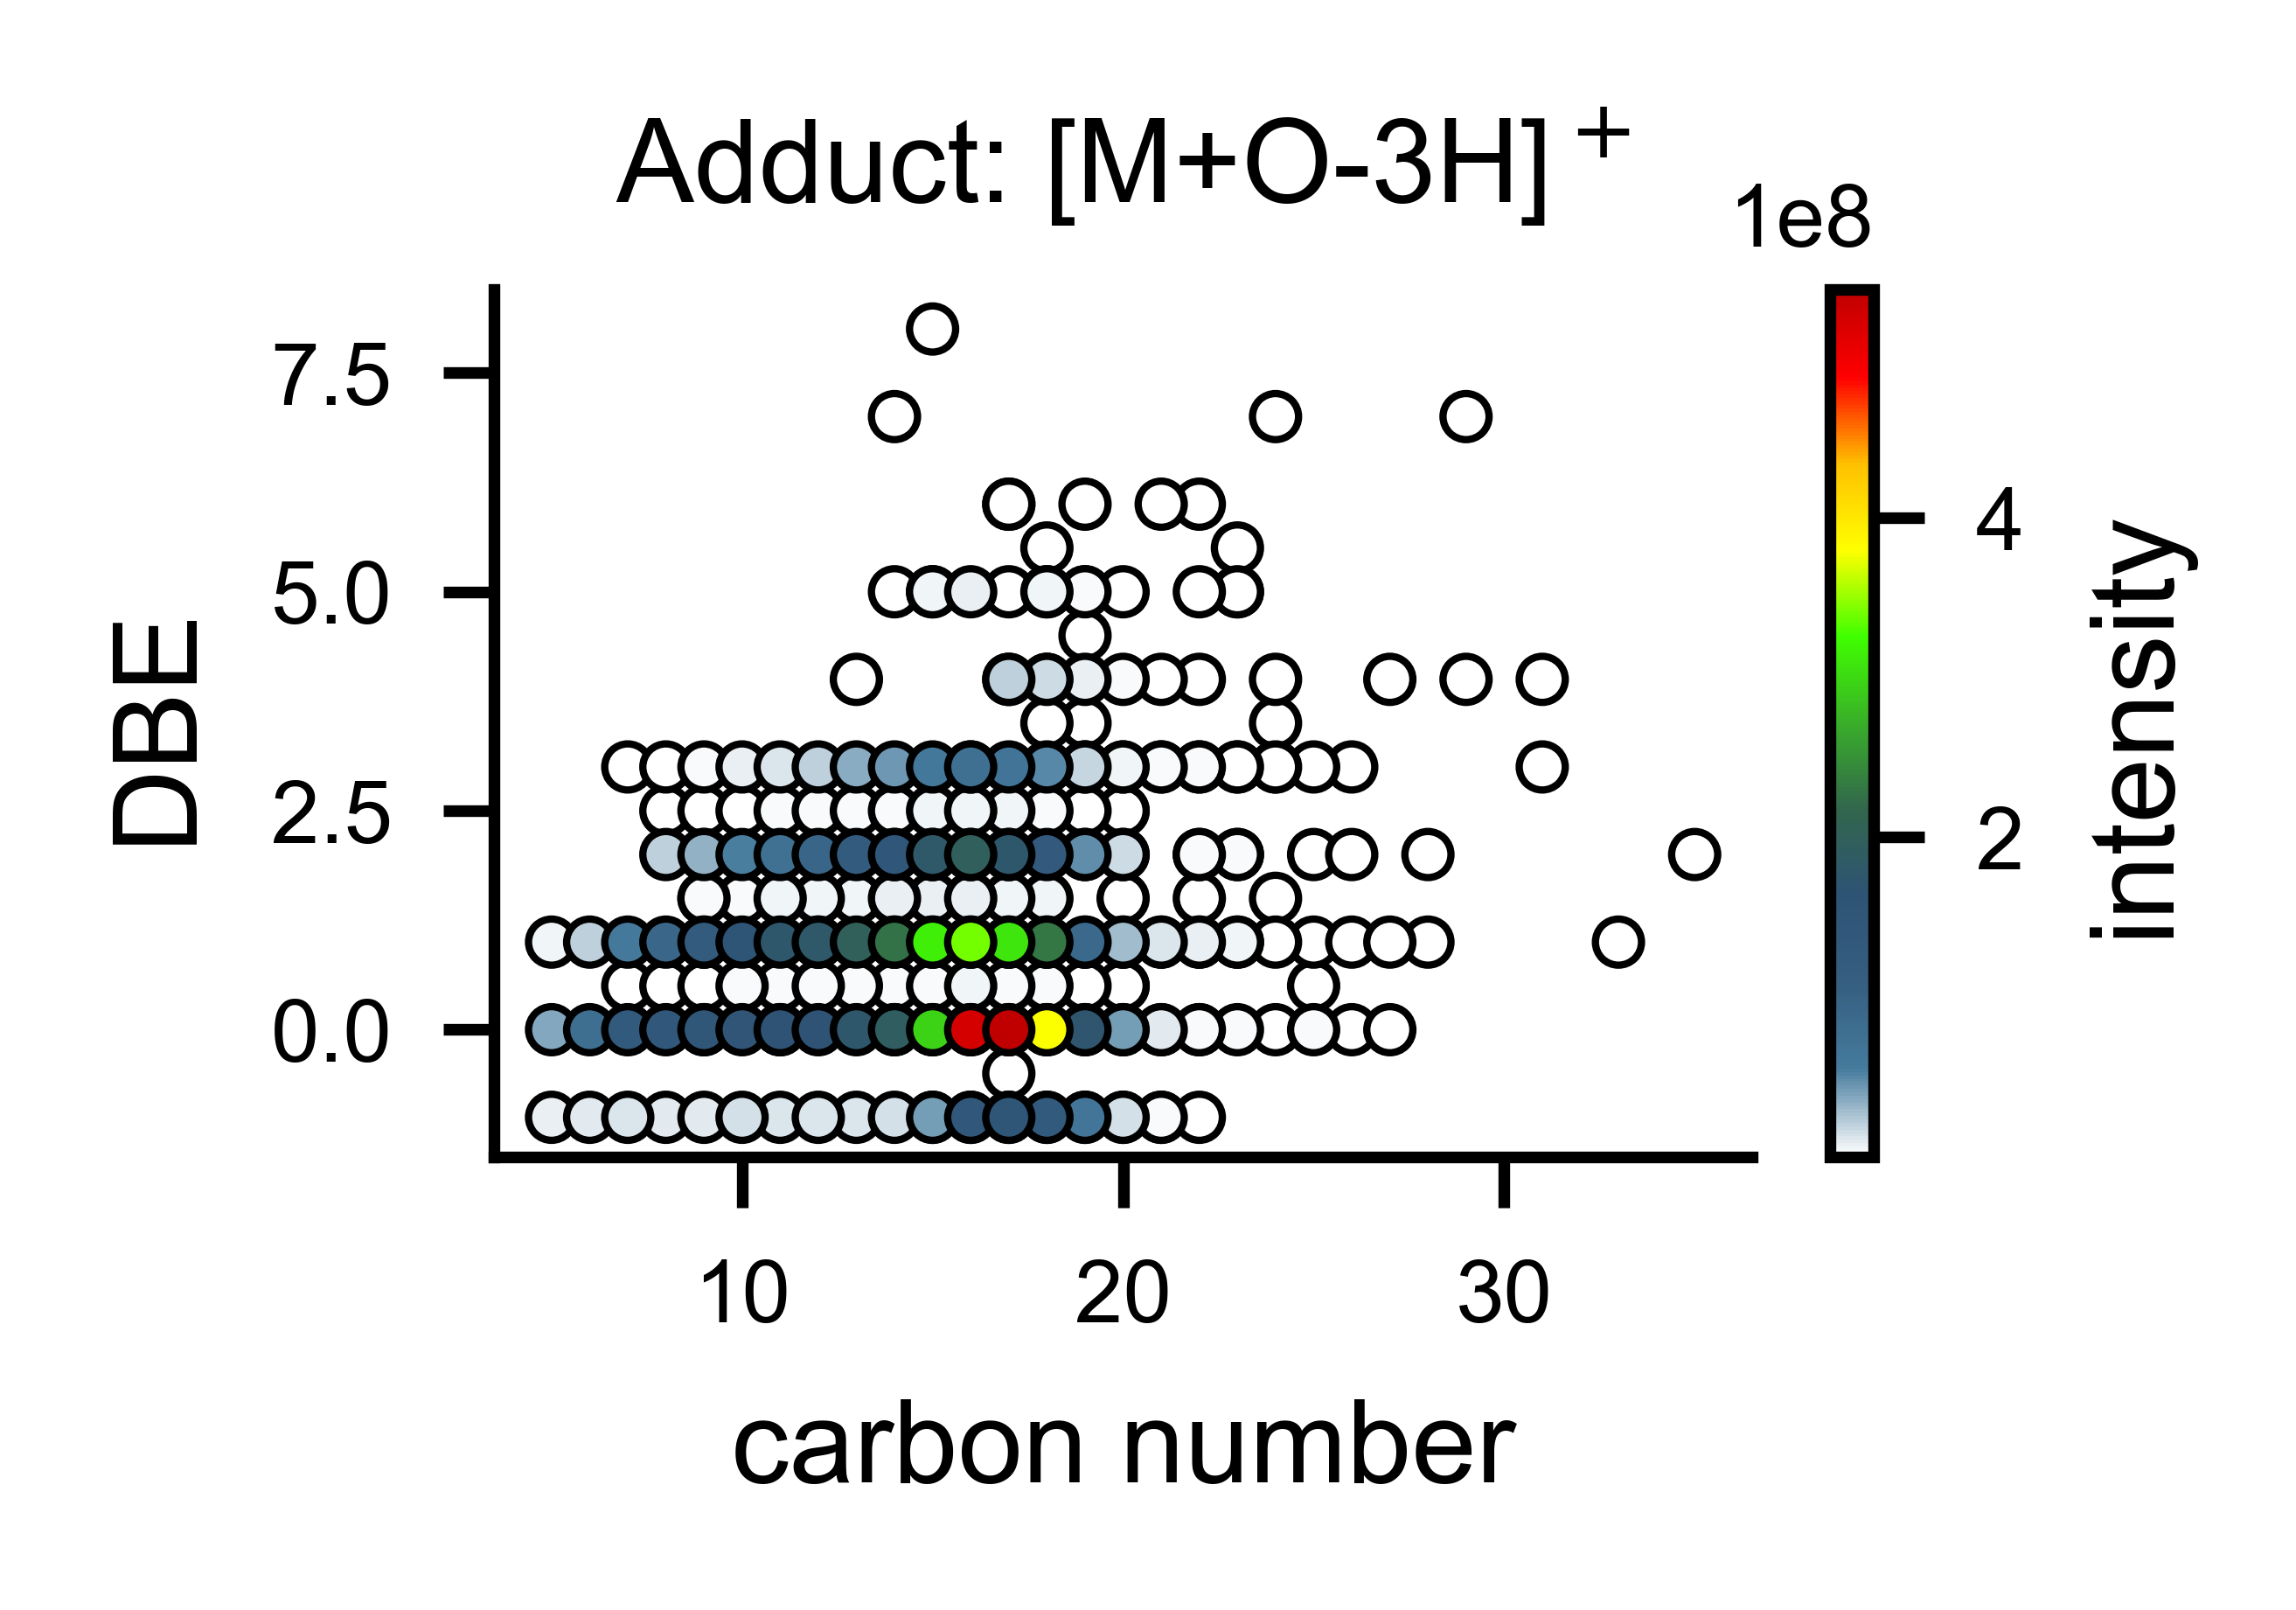

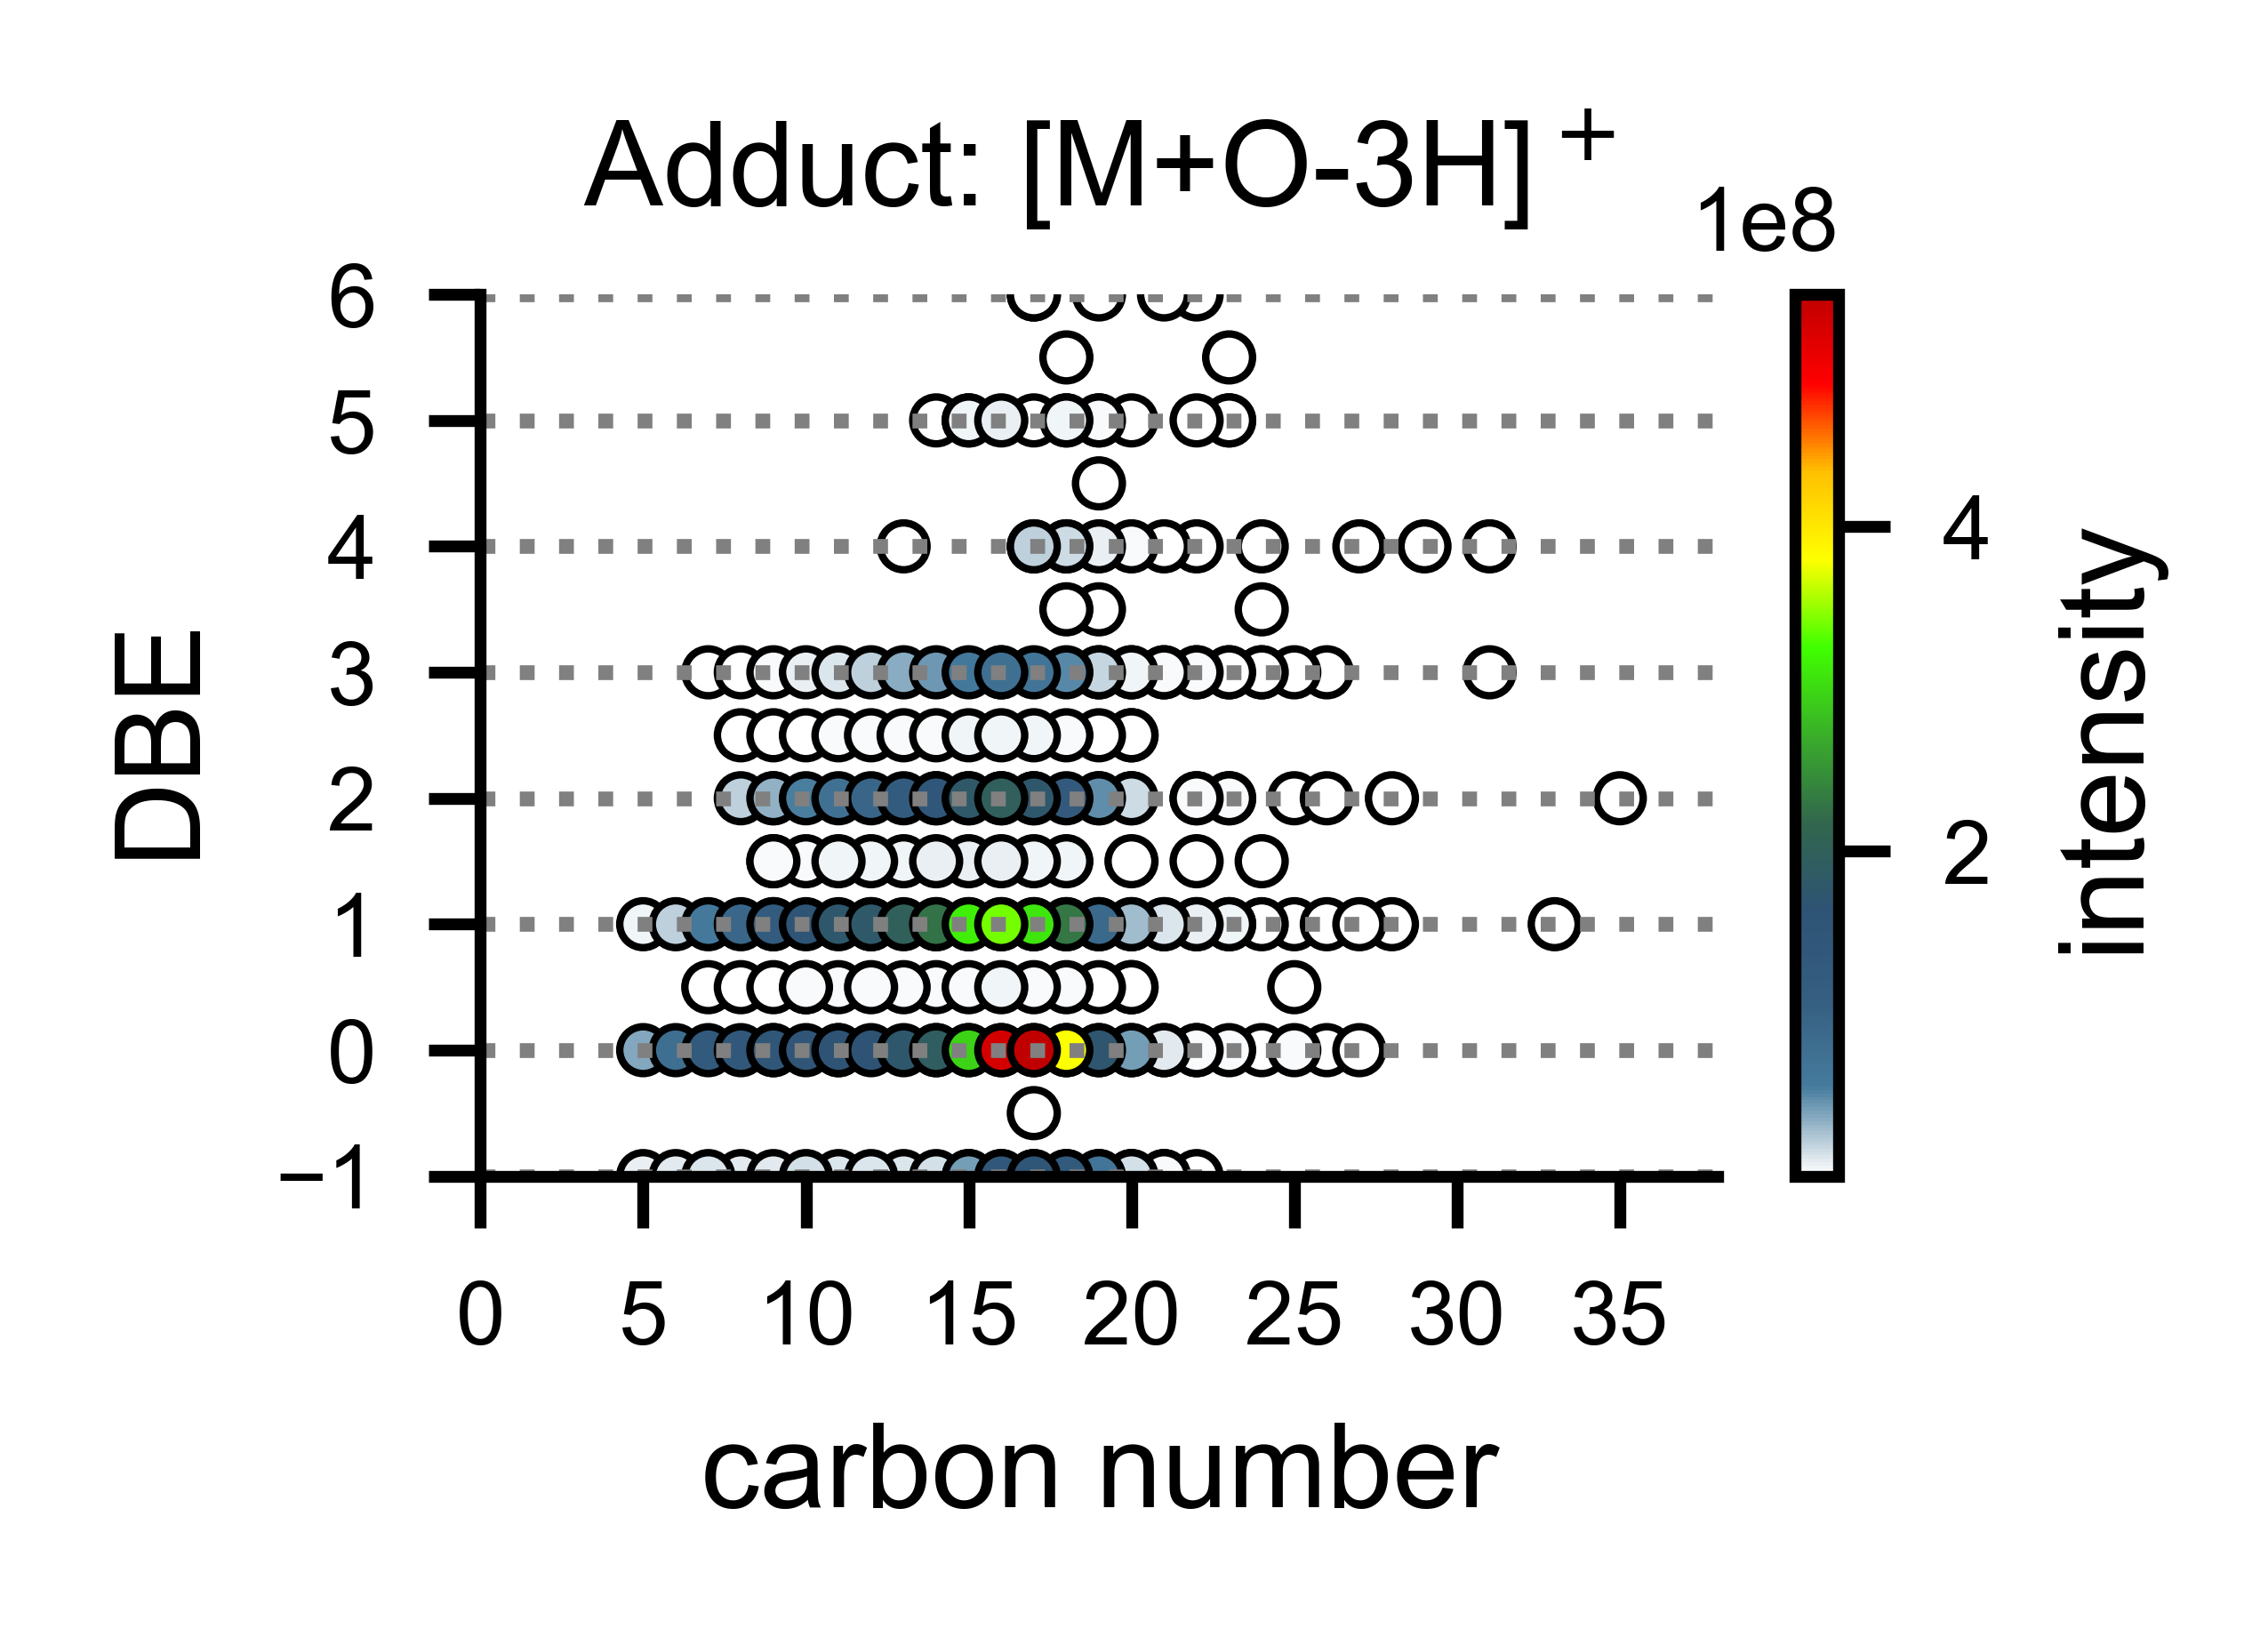

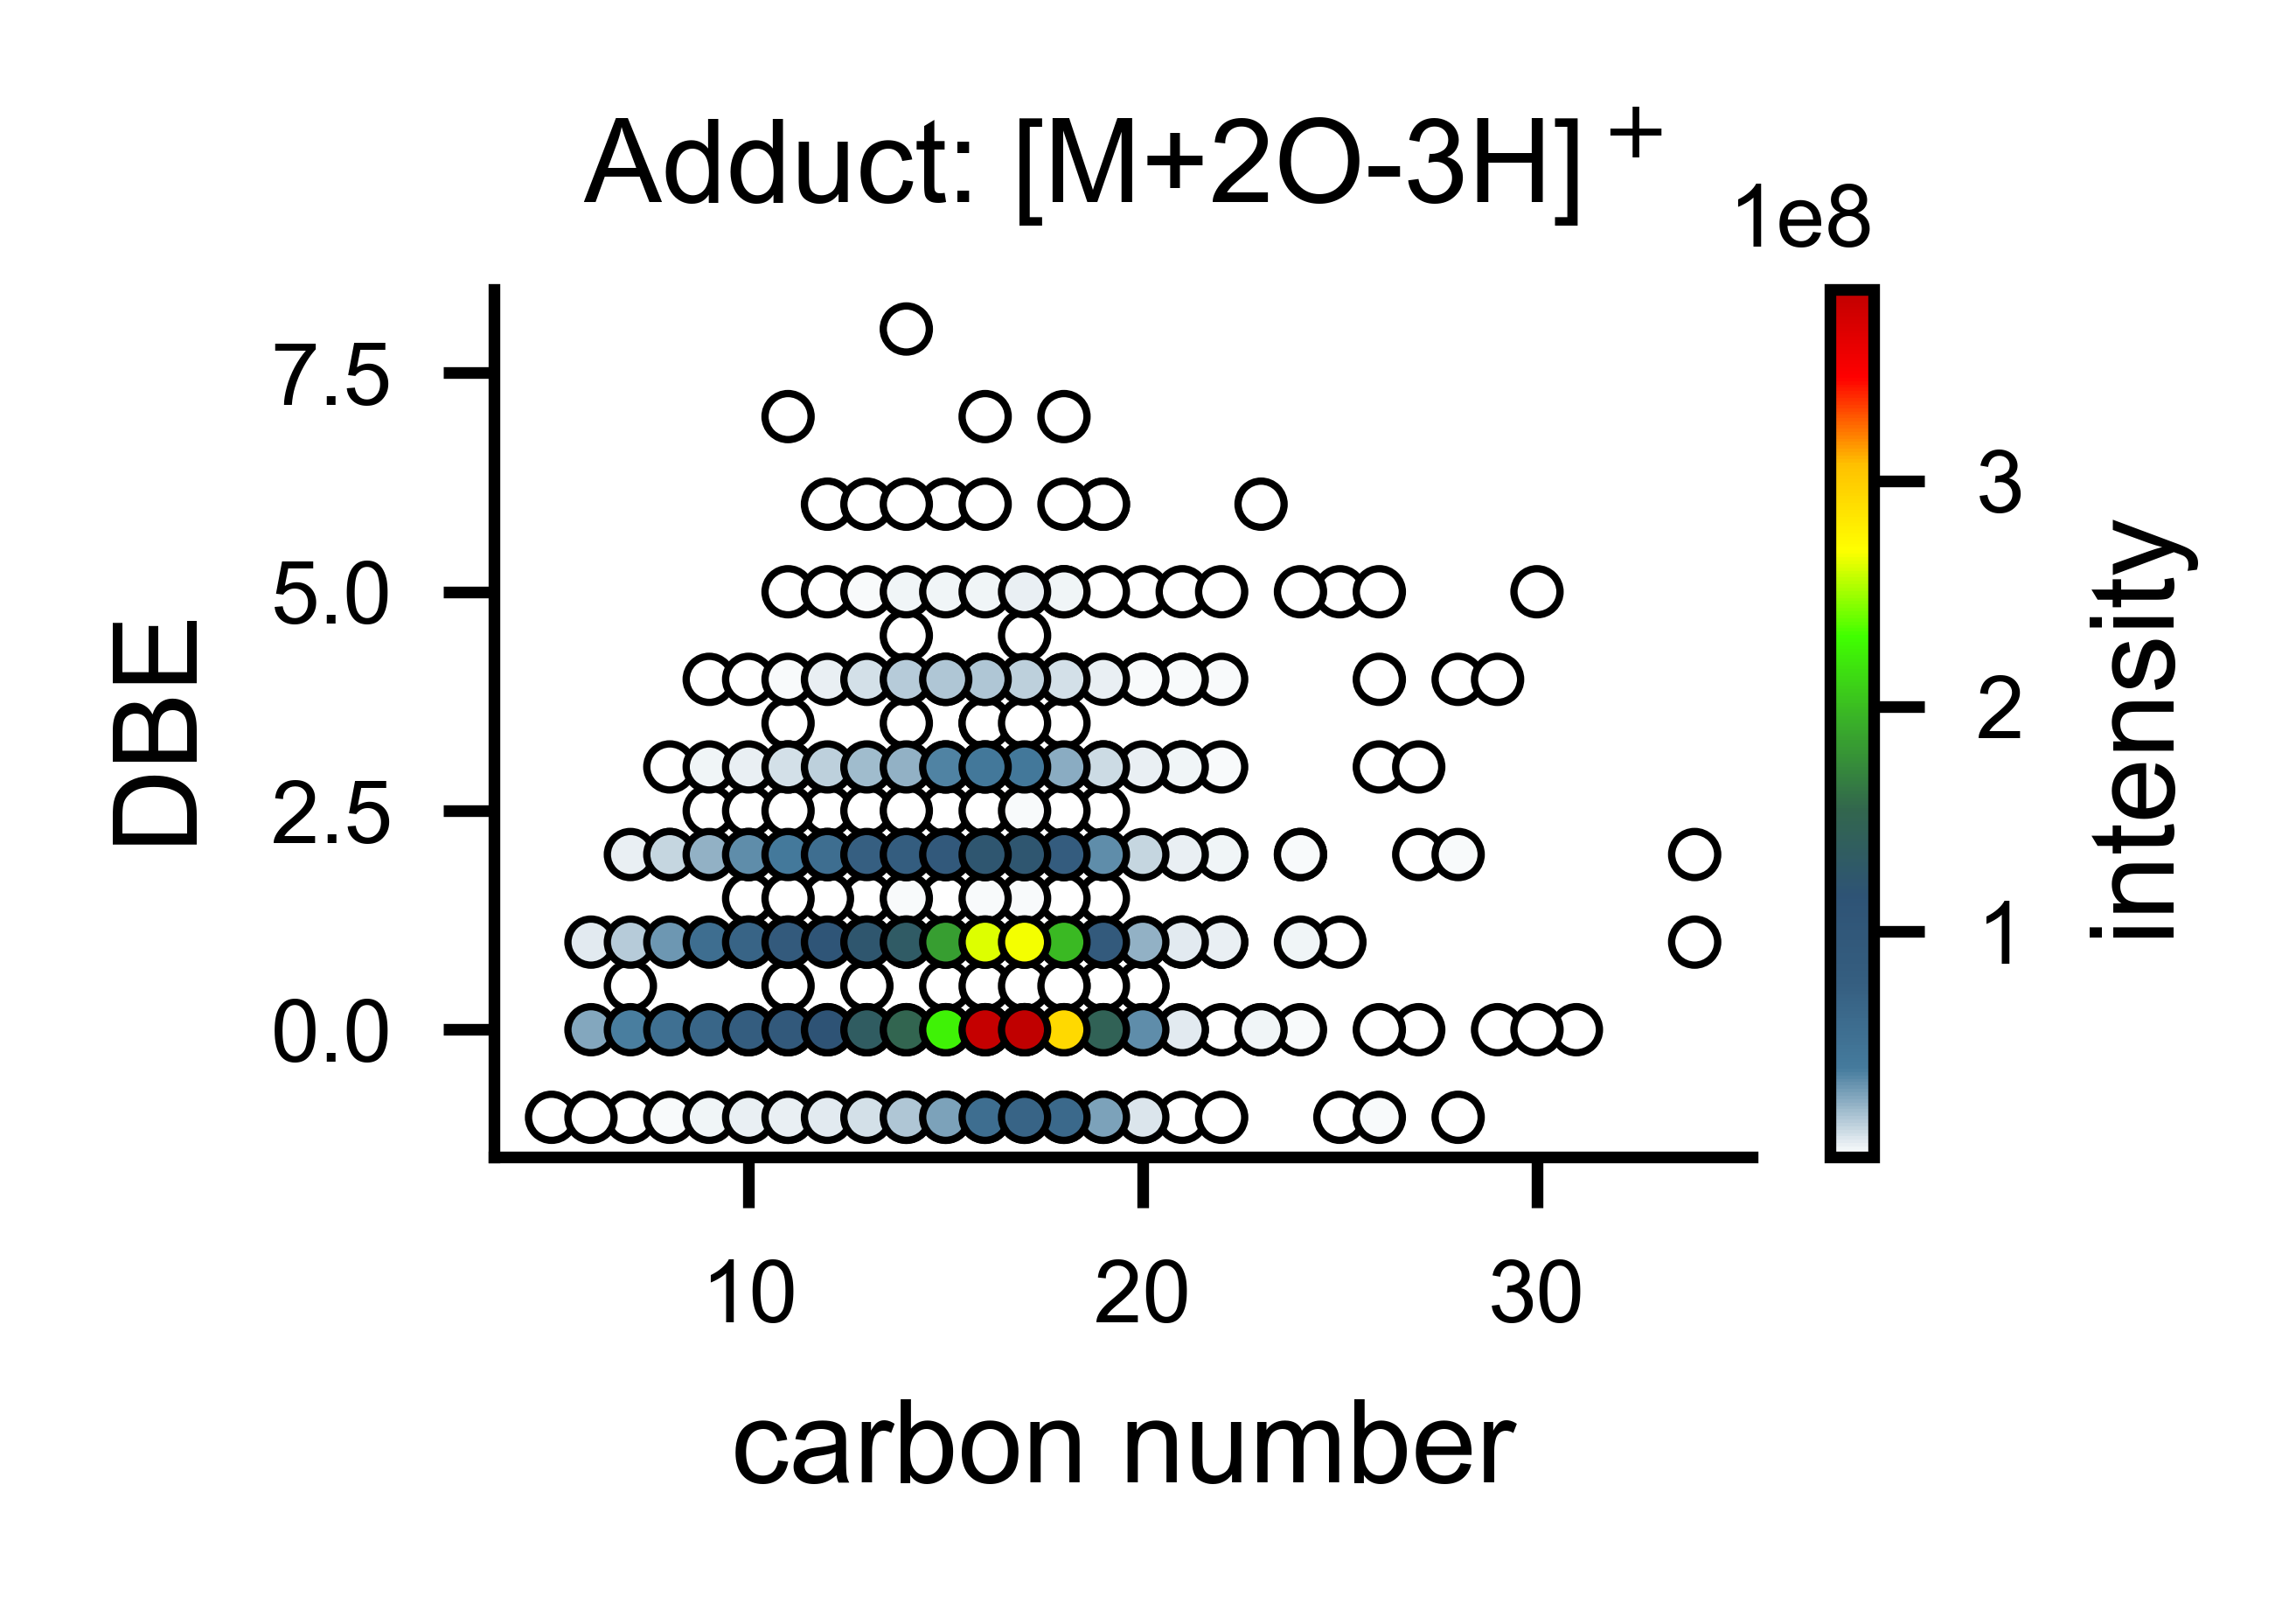

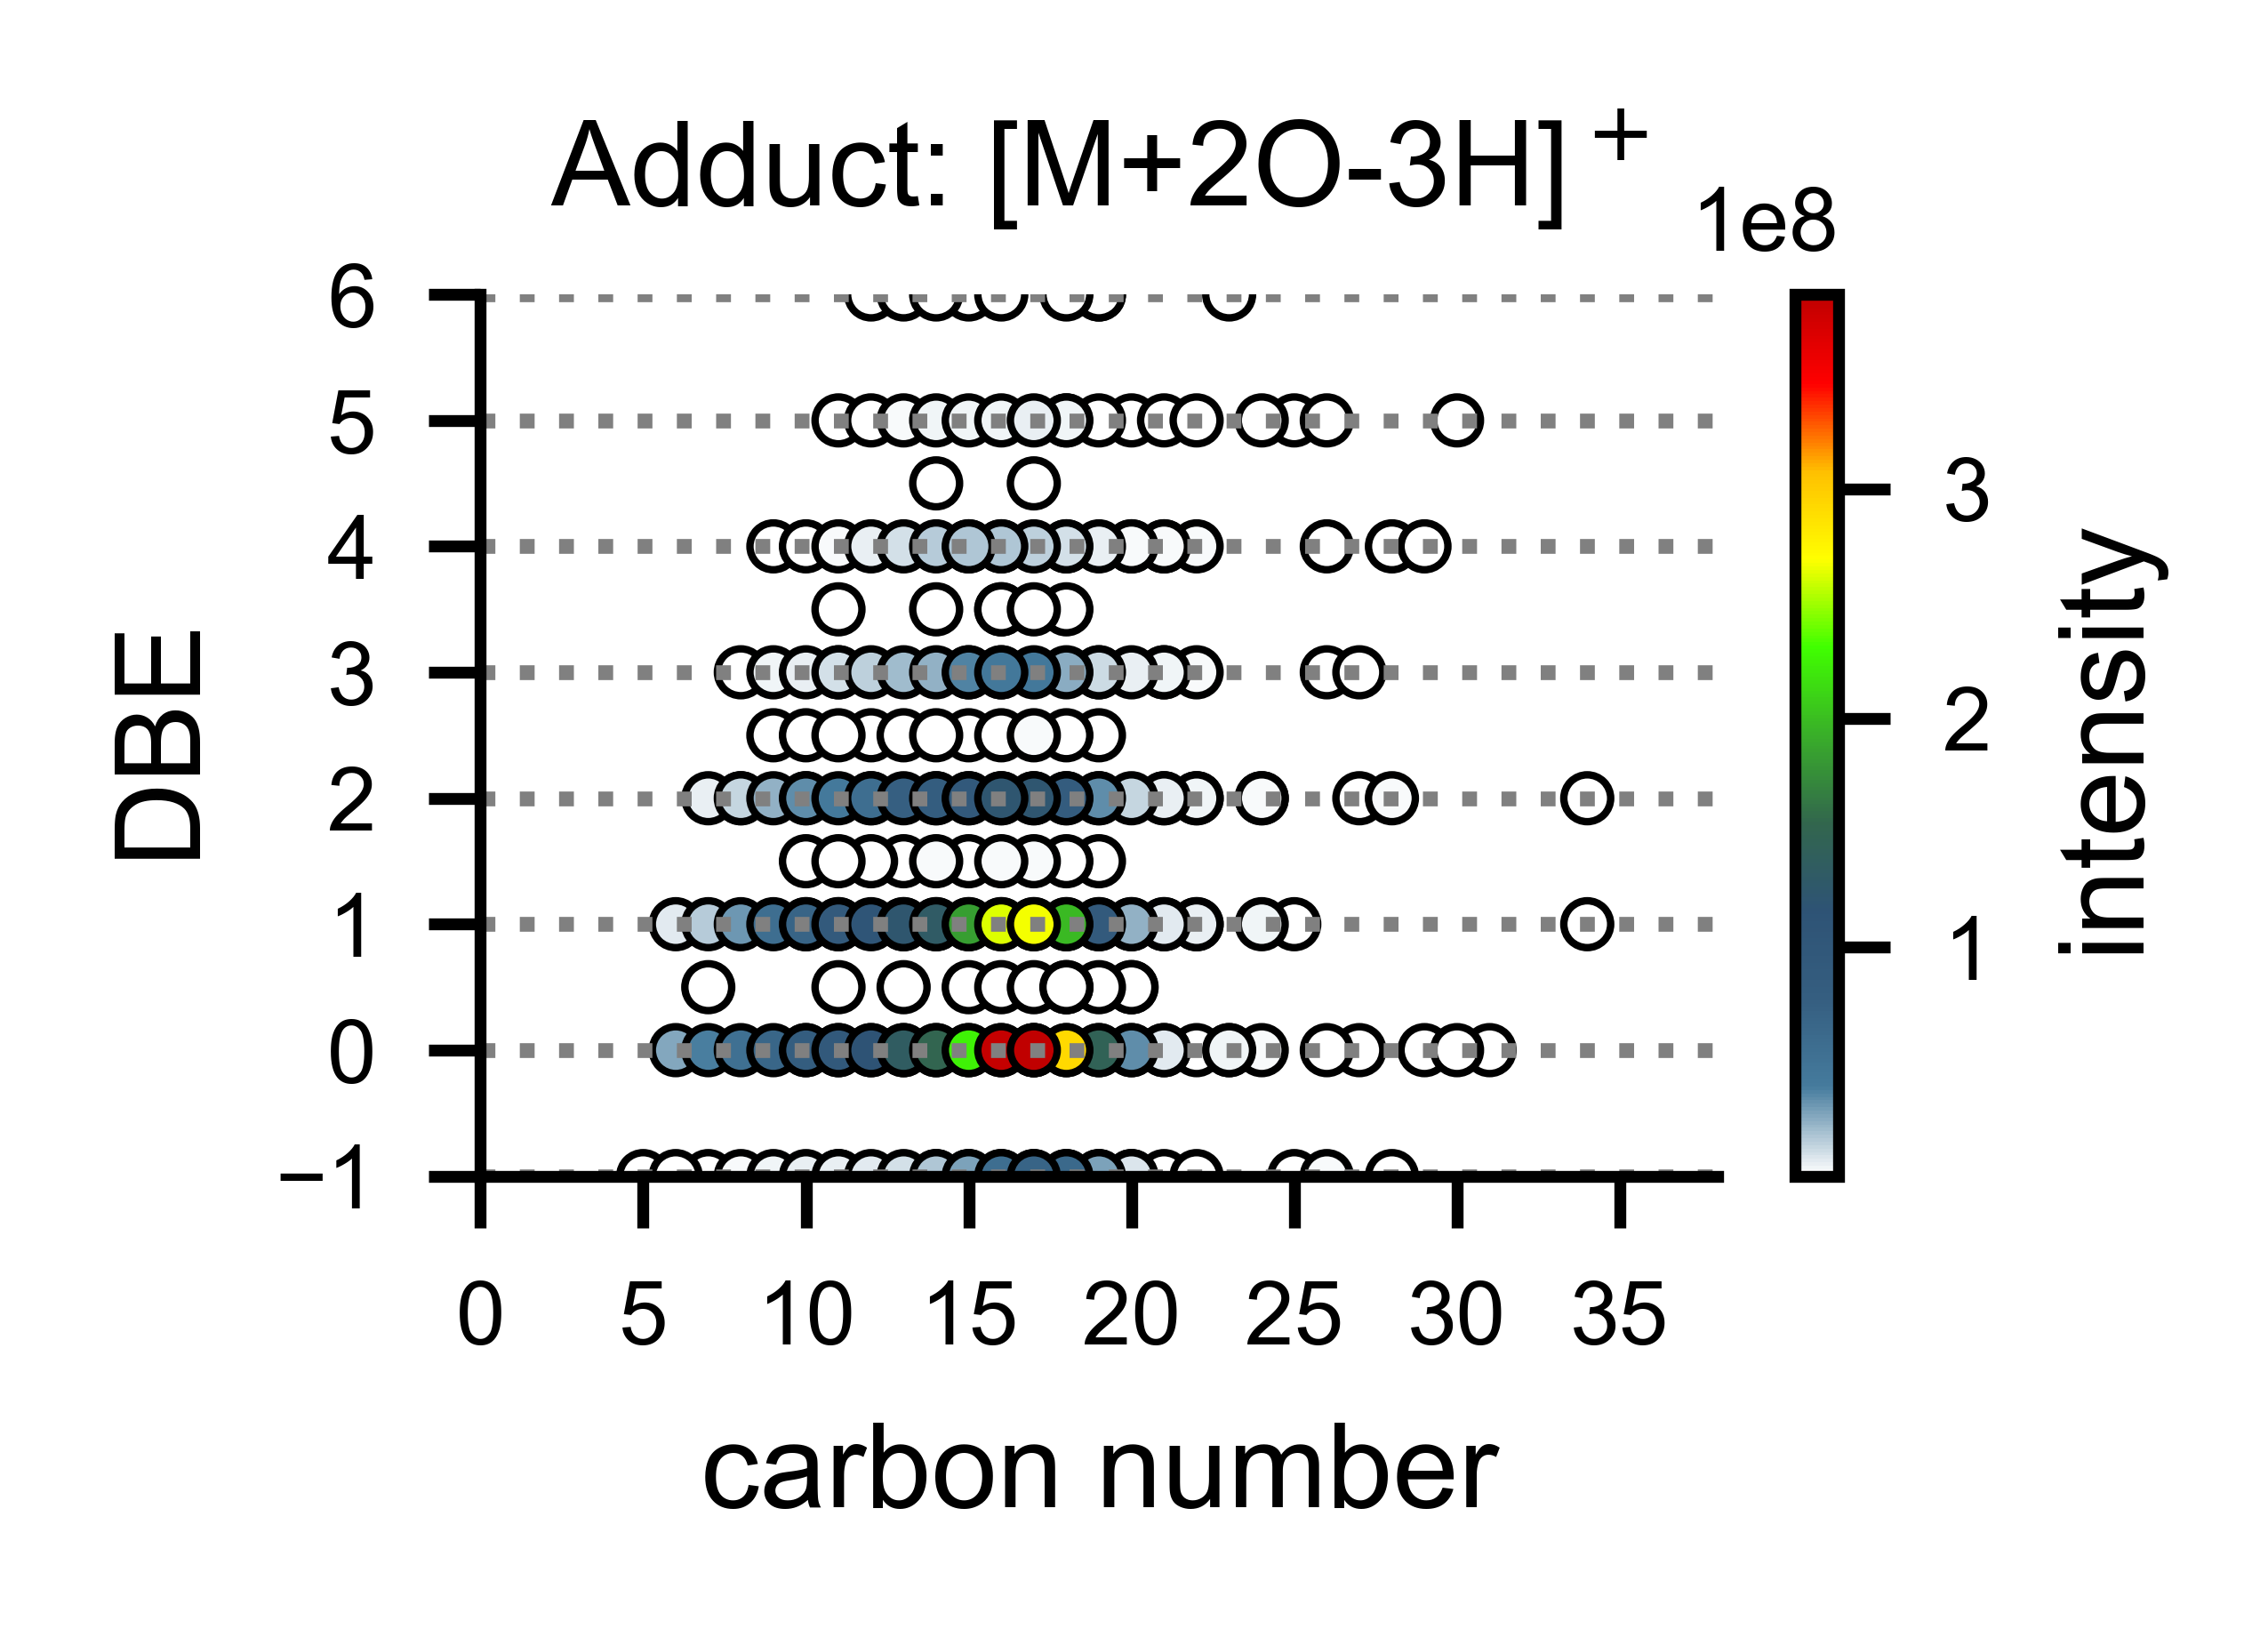

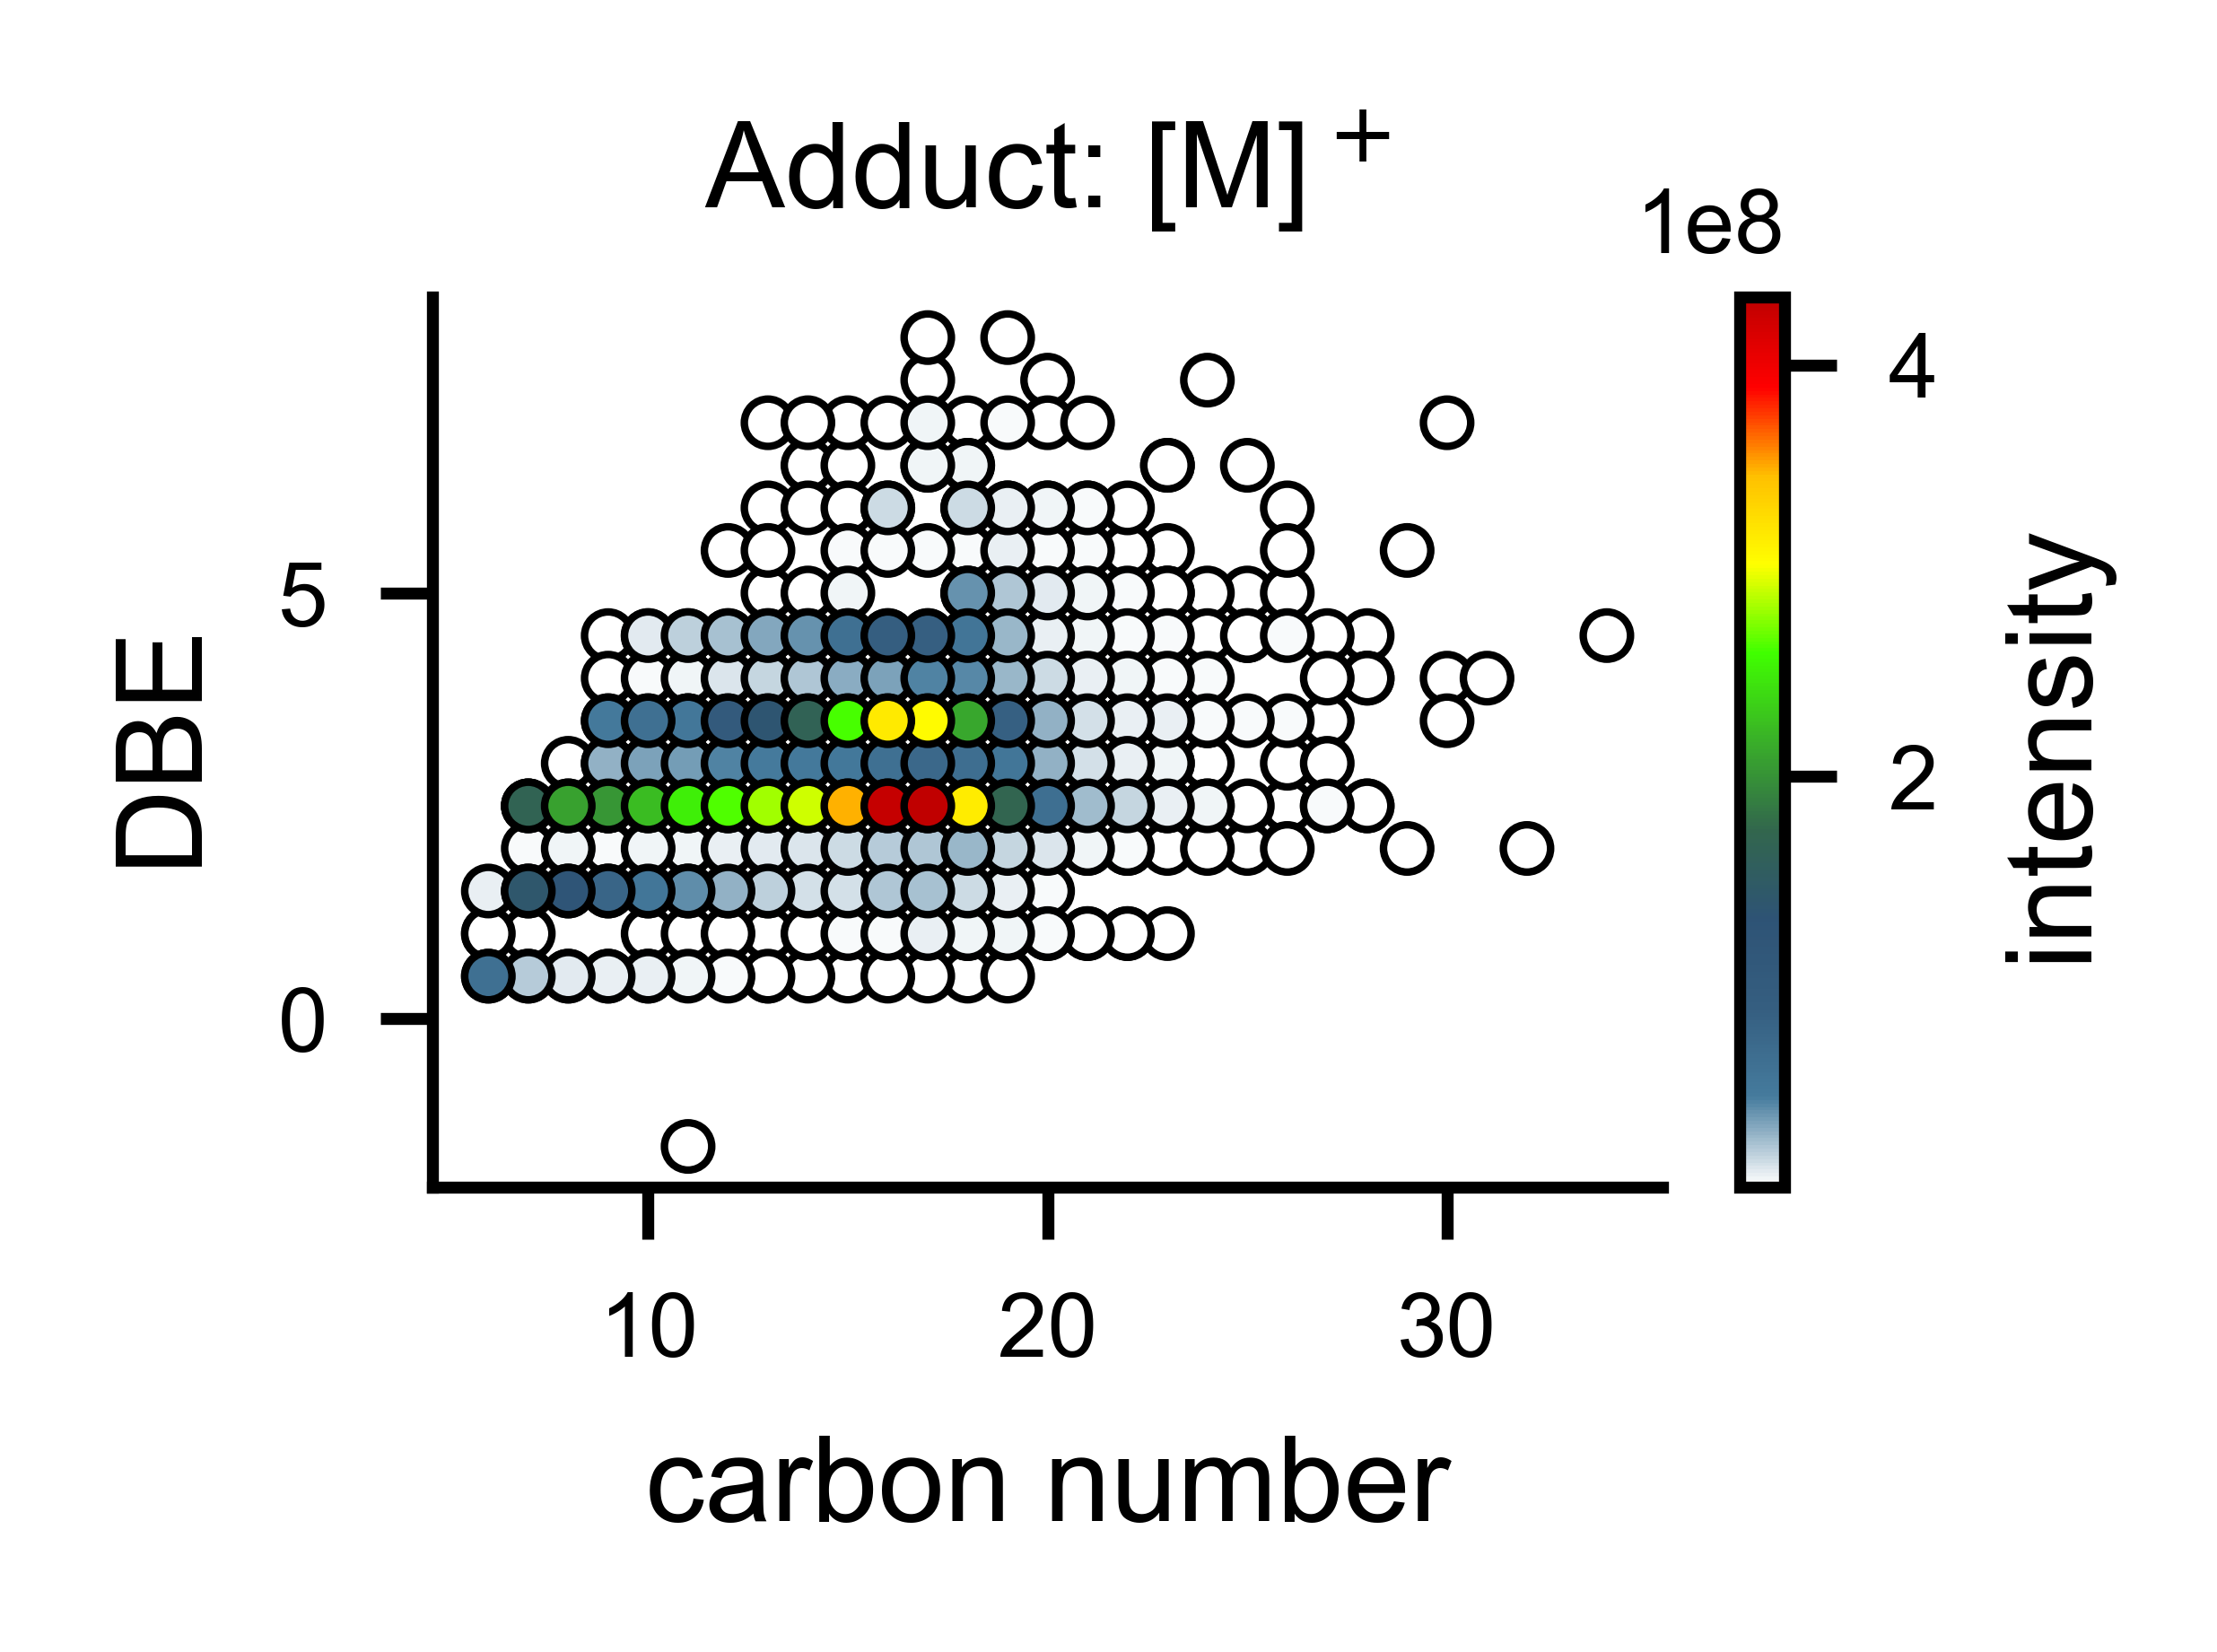

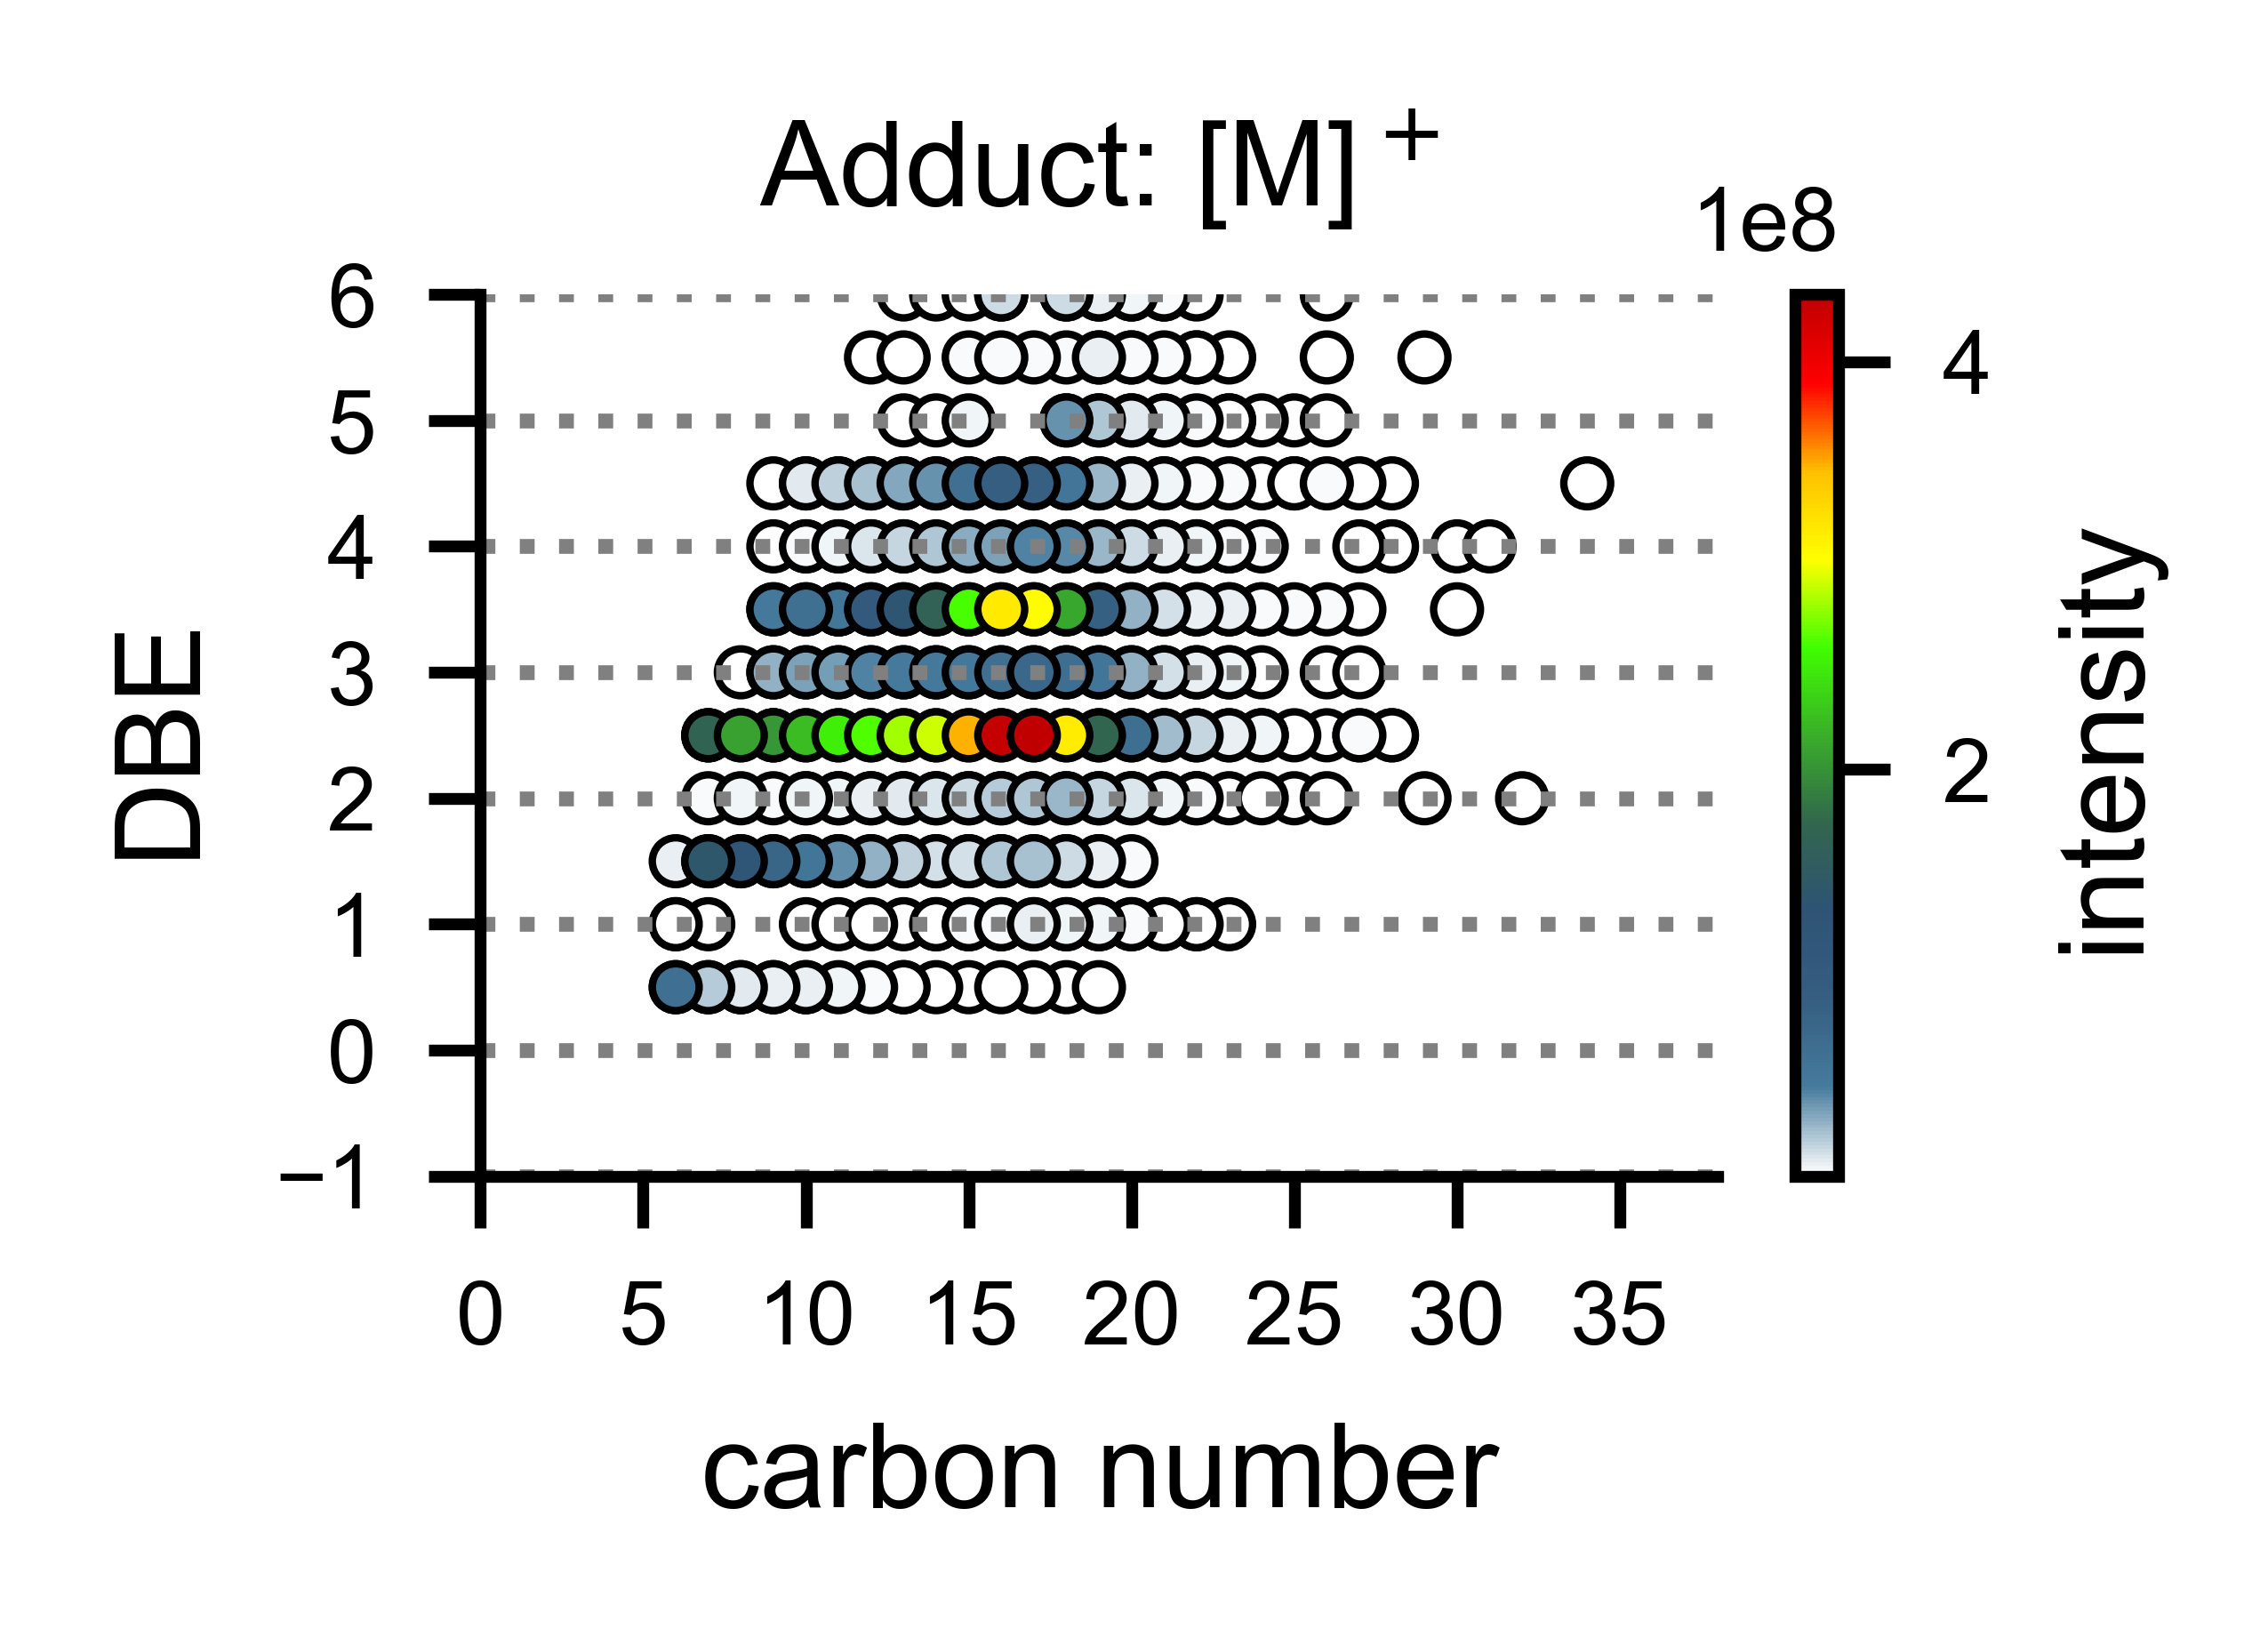

In [11]:
# 3) DBE-Plots für beliebige Addukte, ohne Neuberechnung
plot_dbe_vs_c_publication(df_results, ion_source="iLTP Ar(+) MS(+)", sample="C2C-007",
              adduct_to_plot="[M+O-3H]$^+$",output_prefix="no_cutoff")
plot_dbe_vs_c_publication(df_results, ion_source="iLTP Ar(+) MS(+)", sample="C2C-007",
              adduct_to_plot="[M+2O-3H]$^+$", output_prefix="no_cutoff")
plot_dbe_vs_c_publication(df_results, ion_source="iLTP Ar(+) MS(+)", sample="C2C-007",
              adduct_to_plot="[M]$^+$", output_prefix="no_cutoff")